# Credit Card Fraud Detection
### End-to-end Machine Learning Project

**Objective:** Identify potentially fraudulent credit-card transactions using supervised machine learning.

**Dataset:** Kaggle — [Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)  
Download and extract `creditcard.csv` into the `data/` folder before running this notebook.

**Workflow**
1. Load and inspect data
2. Exploratory data analysis
3. Stratified train/test split
4. Baseline and class-weighted models
5. Validation-based threshold selection
6. Final held-out test evaluation
7. Save the selected model and evaluation artifacts

**Important:** This is an educational project, not a production fraud system. The dataset is highly imbalanced, and `Time`/`Amount` plus anonymized PCA features limit real-world interpretation. We will not use the test set to select the threshold or tune the model.

## 1. Import libraries and configure paths

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
DATA_PATH = Path("data/creditcard.csv")
OUTPUT_DIR = Path("models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

print("Libraries imported.")
print("Notebook working directory:", Path.cwd())
print("Dataset path:", DATA_PATH.resolve())

Libraries imported.
Notebook working directory: /Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection
Dataset path: /Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection/data/creditcard.csv


## 2. Load the dataset

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}\n"
        "Place creditcard.csv inside a folder named data next to this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns.")
display(df.head())
print("\nColumn information:")
df.info()

Loaded 284,807 rows and 31 columns.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

## 3. Basic data-quality checks

In [3]:
print("Shape:", df.shape)
print("\nMissing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nClass counts:")
display(df["Class"].value_counts().rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}))
print("\nClass percentages:")
display((df["Class"].value_counts(normalize=True) * 100).round(4).rename(index={0: "Legitimate (0)", 1: "Fraud (1)"}))

if "Class" not in df.columns:
    raise ValueError("Expected target column 'Class' was not found.")
if not set(df["Class"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected Class to contain binary labels 0 and 1.")

Shape: (284807, 31)

Missing values: 0
Duplicate rows: 1081

Class counts:


Class
Legitimate (0)    284315
Fraud (1)            492
Name: count, dtype: int64


Class percentages:


Class
Legitimate (0)    99.8273
Fraud (1)          0.1727
Name: proportion, dtype: float64

## 4. Exploratory Data Analysis (EDA)

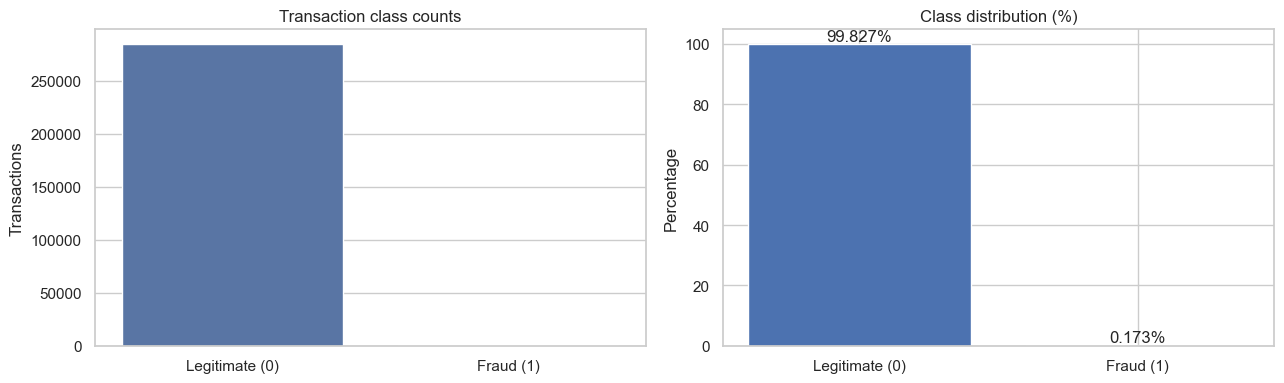

Fraud prevalence: 0.1727%


In [4]:
class_counts = df["Class"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set_title("Transaction class counts")
axes[0].set_xticks([0, 1], ["Legitimate (0)", "Fraud (1)"])
axes[0].set_xlabel("")
axes[0].set_ylabel("Transactions")

class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
axes[1].bar(["Legitimate (0)", "Fraud (1)"], class_pct.values)
axes[1].set_title("Class distribution (%)")
axes[1].set_ylabel("Percentage")
for i, value in enumerate(class_pct.values):
    axes[1].text(i, value, f"{value:.3f}%", ha="center", va="bottom")

plt.tight_layout()
plt.show()

print(f"Fraud prevalence: {df['Class'].mean() * 100:.4f}%")

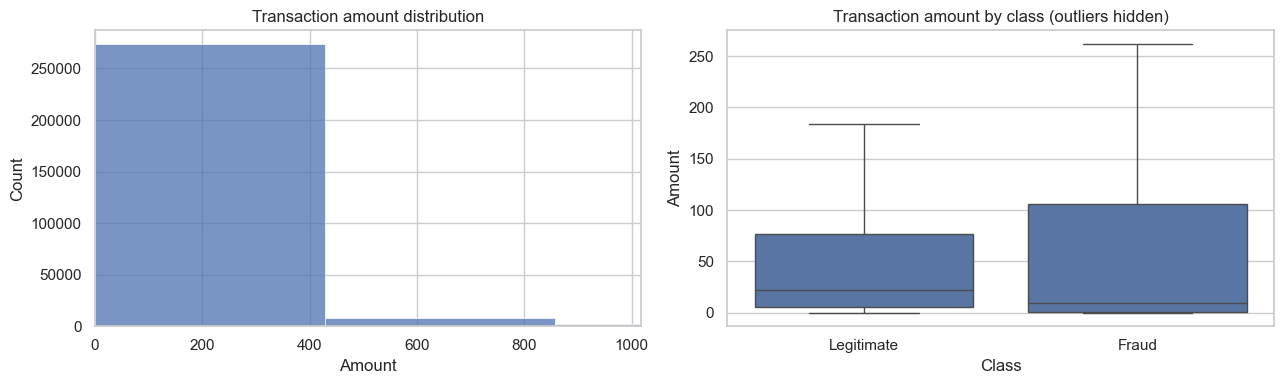

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="Amount", bins=60, ax=axes[0])
axes[0].set_title("Transaction amount distribution")
axes[0].set_xlim(0, df["Amount"].quantile(0.99))

sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=axes[1])
axes[1].set_title("Transaction amount by class (outliers hidden)")
axes[1].set_xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

display(df.groupby("Class")["Amount"].describe().round(2))

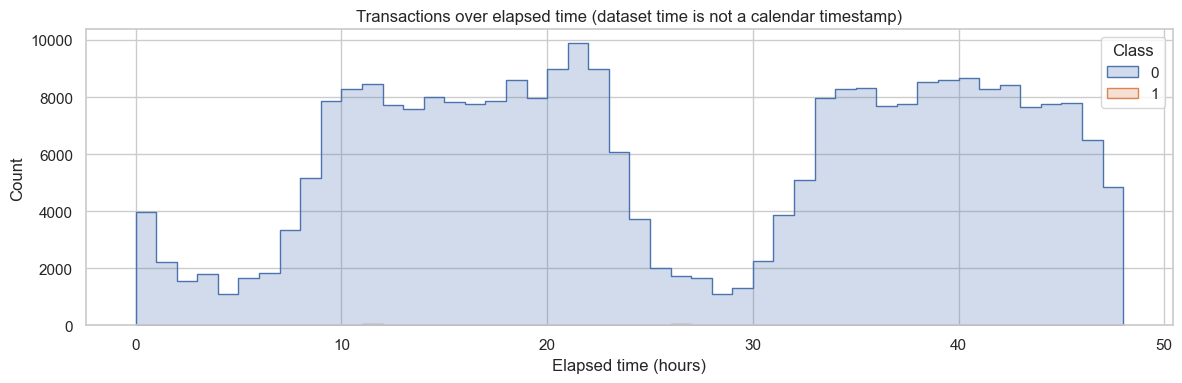

Class,0,1
Time,94838.202,80746.807
Amount,88.291,122.211
V1,0.008,-4.772
V2,-0.006,3.624
V3,0.012,-7.033
V4,-0.008,4.542
V10,0.010,-5.677
V12,0.011,-6.259
V14,0.012,-6.972
V17,0.012,-6.666


In [6]:
if "Time" in df.columns:
    time_hours = df["Time"] / 3600
    plt.figure(figsize=(12, 4))
    sns.histplot(x=time_hours, hue=df["Class"], bins=48, element="step", stat="count", common_norm=False)
    plt.title("Transactions over elapsed time (dataset time is not a calendar timestamp)")
    plt.xlabel("Elapsed time (hours)")
    plt.tight_layout()
    plt.show()

# Compare selected columns; V1-V28 are anonymized transformed features.
selected_cols = [c for c in ["Time", "Amount", "V1", "V2", "V3", "V4", "V10", "V12", "V14", "V17"] if c in df.columns]
display(df[selected_cols + ["Class"]].groupby("Class").mean().T.round(3))

## 5. Prepare features and split the data

`Class` is the target (0 = legitimate, 1 = fraud). We use a stratified split so the rare fraud class is represented in train, validation, and test sets.

- 60% training
- 20% validation (threshold selection)
- 20% final test (used once for final evaluation)

The test set is held out from model and threshold selection.

In [25]:
from sklearn.model_selection import StratifiedGroupKFold

X = df.drop(columns=["Class"]).copy()
y = df["Class"].astype(int).copy()

# Identical feature vectors receive the same group ID.
groups = pd.util.hash_pandas_object(
    X, index=False
).to_numpy()

# Five-fold group-aware split:
# Fold 1 is test, fold 2 is validation, folds 3–5 are training.
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(splitter.split(X, y, groups=groups))

train_idx = np.concatenate([
    folds[2][1],
    folds[3][1],
    folds[4][1]
])
val_idx = folds[1][1]
test_idx = folds[0][1]

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("Train:", X_train.shape, "| fraud:", int(y_train.sum()))
print("Validation:", X_val.shape, "| fraud:", int(y_val.sum()))
print("Test:", X_test.shape, "| fraud:", int(y_test.sum()))

print("\nFraud rates:")
print("Train:", round(y_train.mean() * 100, 4), "%")
print("Validation:", round(y_val.mean() * 100, 4), "%")
print("Test:", round(y_test.mean() * 100, 4), "%")

Train: (170856, 30) | fraud: 294
Validation: (56974, 30) | fraud: 84
Test: (56977, 30) | fraud: 114

Fraud rates:
Train: 0.1721 %
Validation: 0.1474 %
Test: 0.2001 %


## 6. Define models

We compare:
- **Dummy baseline:** predicts all transactions as legitimate; this illustrates why accuracy alone is misleading.
- **Logistic Regression:** class-weighted linear baseline.
- **Random Forest:** class-weighted nonlinear model.

Scaling is included in the Logistic Regression pipeline. Tree models do not require feature scaling. No resampling is performed before the split; this avoids leakage.

In [26]:
from sklearn.dummy import DummyClassifier

models = {
    "Dummy (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (balanced)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            solver="liblinear",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest (balanced)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=250,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}
print("Models defined:", ", ".join(models.keys()))

Models defined: Dummy (majority class), Logistic Regression (balanced), Random Forest (balanced)


## 7. Train models and compare validation performance

In [27]:
def safe_average_precision(y_true, scores):
    return average_precision_score(y_true, scores)

def get_scores(estimator, X_data):
    if hasattr(estimator, "predict_proba"):
        return estimator.predict_proba(X_data)[:, 1]
    if hasattr(estimator, "decision_function"):
        raw = estimator.decision_function(X_data)
        # Scores only need to rank observations for ROC-AUC/AP.
        return raw
    return estimator.predict(X_data).astype(float)

fitted_models = {}
validation_rows = []

for name, estimator in models.items():
    print(f"Training: {name}")
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator
    val_scores = get_scores(estimator, X_val)
    # Default threshold of 0.5 for probability models; dummy remains all-negative.
    val_pred = estimator.predict(X_val)
    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, val_scores),
        "PR-AUC (Average Precision)": safe_average_precision(y_val, val_scores)
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "PR-AUC (Average Precision)", ascending=False
).reset_index(drop=True)
display(validation_results.round(4))

Training: Dummy (majority class)
Training: Logistic Regression (balanced)
Training: Random Forest (balanced)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision)
0,Random Forest (balanced),0.9995,0.8841,0.7262,0.7974,0.9724,0.8069
1,Logistic Regression (balanced),0.9776,0.0558,0.8929,0.1051,0.9767,0.6814
2,Dummy (majority class),0.9985,0.0000,0.0000,0.0000,0.5000,0.0015


## 8. Plot validation Precision–Recall curves

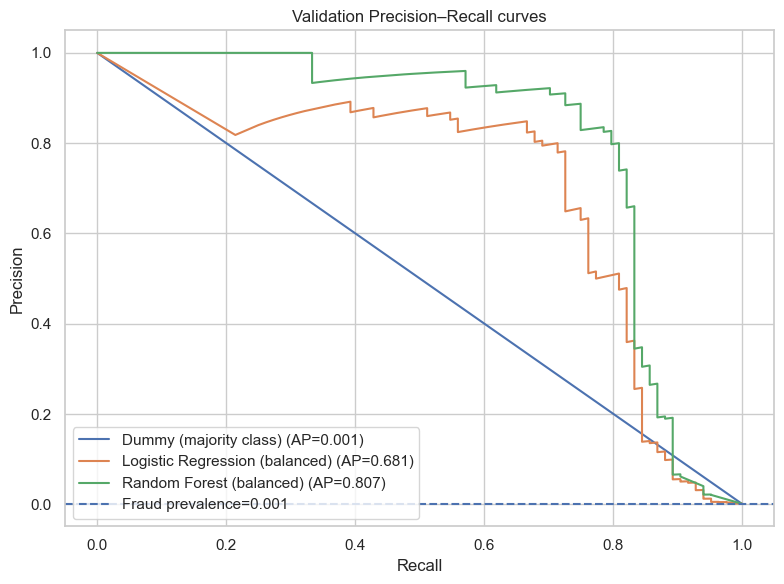

In [28]:
plt.figure(figsize=(8, 6))
for name, estimator in fitted_models.items():
    scores = get_scores(estimator, X_val)
    precision, recall, _ = precision_recall_curve(y_val, scores)
    ap = average_precision_score(y_val, scores)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.axhline(y=y_val.mean(), linestyle="--", label=f"Fraud prevalence={y_val.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall curves")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Select a model and tune its threshold on validation data

For fraud detection, a threshold of 0.5 is not automatically best. Here, we select the model with the highest validation Average Precision, then choose a threshold that maximizes validation F1. In a real deployment, the threshold should reflect the cost of false positives and missed fraud, and may be selected to meet a minimum precision/recall target.

**The test set is not used for this decision.**

In [29]:
best_name = validation_results.iloc[0]["Model"]
best_model = fitted_models[best_name]
val_scores = get_scores(best_model, X_val)

precision, recall, thresholds = precision_recall_curve(y_val, val_scores)

# precision and recall have one more element than thresholds; thresholds map to all but last point.
if len(thresholds) == 0:
    best_threshold = 0.5
    threshold_table = pd.DataFrame()
else:
    f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best_idx = int(np.nanargmax(f1_values))
    best_threshold = float(thresholds[best_idx])
    threshold_table = pd.DataFrame({
        "Threshold": thresholds,
        "Precision": precision[:-1],
        "Recall": recall[:-1],
        "F1": f1_values
    }).sort_values("F1", ascending=False)

print("Selected model:", best_name)
print(f"Validation-selected threshold (max F1): {best_threshold:.6f}")
print("\nTop 10 validation thresholds by F1:")
display(threshold_table.head(10).round(4))

Selected model: Random Forest (balanced)
Validation-selected threshold (max F1): 0.443814

Top 10 validation thresholds by F1:


,Threshold,Precision,Recall,F1
1351,0.4438,0.8873,0.7500,0.8129
1341,0.1679,0.8272,0.7976,0.8121
1343,0.2159,0.8354,0.7857,0.8098
1355,0.5479,0.9104,0.7262,0.8079
1350,0.3675,0.8750,0.7500,0.8077
1340,0.1558,0.8171,0.7976,0.8072
1352,0.4959,0.8857,0.7381,0.8052
1342,0.1719,0.8250,0.7857,0.8049
1337,0.1278,0.8000,0.8095,0.8047
1354,0.5237,0.8971,0.7262,0.8026


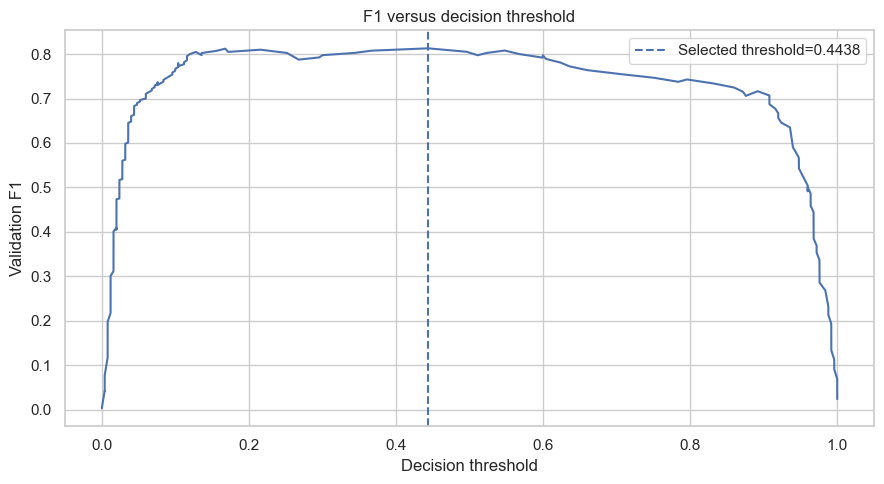

In [30]:
plt.figure(figsize=(9, 5))
plt.plot(thresholds, threshold_table.set_index("Threshold").reindex(thresholds)["F1"].values if len(thresholds) else [])
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold={best_threshold:.4f}")
plt.xlabel("Decision threshold")
plt.ylabel("Validation F1")
plt.title("F1 versus decision threshold")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Evaluate once on the held-out test set

In [31]:
test_scores = get_scores(best_model, X_test)
test_pred_default = (test_scores >= 0.5).astype(int)
test_pred_tuned = (test_scores >= best_threshold).astype(int)

def metric_row(label, y_true, y_pred, scores):
    return {
        "Setting": label,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC (Average Precision)": average_precision_score(y_true, scores),
        "Fraud caught": int(((y_true == 1) & (y_pred == 1)).sum()),
        "False alarms": int(((y_true == 0) & (y_pred == 1)).sum()),
        "Fraud missed": int(((y_true == 1) & (y_pred == 0)).sum())
    }

test_results = pd.DataFrame([
    metric_row("Default threshold 0.5", y_test, test_pred_default, test_scores),
    metric_row(f"Tuned threshold {best_threshold:.4f}", y_test, test_pred_tuned, test_scores)
])
display(test_results.round(4))

,Setting,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (Average Precision),Fraud caught,False alarms,Fraud missed
0,Default threshold 0.5,0.9995,0.9570,0.7807,0.8599,0.9759,0.8861,89,4,25
1,Tuned threshold 0.4438,0.9995,0.9479,0.7982,0.8667,0.9759,0.8861,91,5,23


Classification report at tuned threshold (0.443814):
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.95      0.80      0.87       114

    accuracy                           1.00     56977
   macro avg       0.97      0.90      0.93     56977
weighted avg       1.00      1.00      1.00     56977



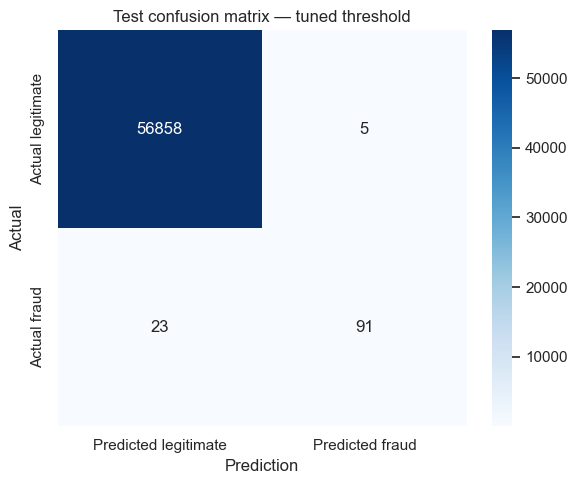

In [32]:
print(f"Classification report at tuned threshold ({best_threshold:.6f}):")
print(classification_report(y_test, test_pred_tuned, target_names=["Legitimate", "Fraud"], zero_division=0))

cm = confusion_matrix(y_test, test_pred_tuned, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted legitimate", "Predicted fraud"],
    yticklabels=["Actual legitimate", "Actual fraud"]
)
plt.title("Test confusion matrix — tuned threshold")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

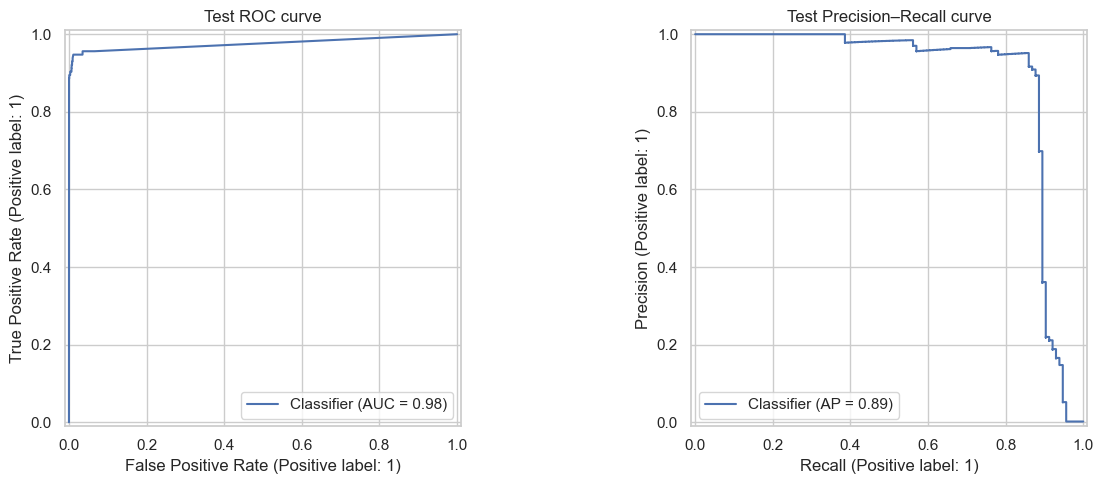

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[0])
axes[0].set_title("Test ROC curve")

PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[1])
axes[1].set_title("Test Precision–Recall curve")
plt.tight_layout()
plt.show()

## 11. Inspect example predictions

The table below shows test transactions with their actual label, predicted fraud label, and model score. A score is a ranking/risk signal; it should not be interpreted as a calibrated real-world fraud probability without additional calibration and validation.

In [34]:
prediction_preview = X_test.copy()
prediction_preview["Actual_Class"] = y_test
prediction_preview["Fraud_Score"] = test_scores
prediction_preview["Predicted_Class"] = test_pred_tuned
prediction_preview["Correct"] = (
    prediction_preview["Actual_Class"].to_numpy()
    == prediction_preview["Predicted_Class"].to_numpy()
)
display(
    prediction_preview.sort_values("Fraud_Score", ascending=False)
    .head(15)
    .round(4)
)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Actual_Class,Fraud_Score,Predicted_Class,Correct
143336,85285.0,-6.7134,3.9211,-9.7467,5.1483,-5.1516,-2.0994,-5.9378,3.5788,-4.6850,-8.5378,6.3490,-8.6816,0.2512,-11.6080,-0.3516,-5.3636,-11.9391,-3.5836,0.8974,0.1357,0.9543,-0.4511,0.1272,-0.3394,0.3941,1.0753,1.6499,-0.3949,252.92,1,1.0000,1,True
143335,85285.0,-6.7134,3.9211,-9.7467,5.1483,-5.1516,-2.0994,-5.9378,3.5788,-4.6850,-8.5378,6.3490,-8.6816,0.2512,-11.6080,-0.3516,-5.3636,-11.9391,-3.5836,0.8974,0.1357,0.9543,-0.4511,0.1272,-0.3394,0.3941,1.0753,1.6499,-0.3949,252.92,1,1.0000,1,True
230476,146344.0,-0.0997,2.7954,-6.4239,3.2475,-1.6323,-2.7667,-2.3122,0.9610,-1.8960,-4.9193,3.0537,-5.2978,-1.4660,-7.0359,1.9971,-3.8362,-2.5152,-0.8646,2.3289,0.3409,0.6477,0.1266,0.2040,0.0085,-0.1745,0.5753,0.1529,-0.0982,94.82,1,0.9960,1,True
15751,27187.0,-24.5902,14.0446,-26.2787,6.3201,-18.2245,-4.6100,-17.6810,16.2136,-3.7941,-8.3728,4.9017,-6.8728,0.7698,-6.8266,-0.0544,-6.0850,-12.3753,-4.8103,0.9367,1.6492,1.7771,-1.8049,-1.1406,0.1522,1.7160,-0.2205,1.4350,0.4225,99.99,1,0.9960,1,True
42936,41305.0,-12.9809,6.7205,-13.4556,8.6986,-11.4796,-2.6815,-14.0193,8.2182,-7.9309,-12.6959,5.5894,-11.9609,1.5387,-9.8872,0.6340,-11.3502,-21.7102,-8.8595,3.6297,-0.8433,2.5496,-0.5322,-0.2351,0.6732,0.2266,-0.0062,-1.1857,-0.7474,59.68,1,0.9960,1,True
223618,143456.0,-2.0066,3.6766,-5.4638,7.2321,-1.6279,-0.9968,-4.2998,2.2689,-3.6511,-4.4009,4.2132,-5.7378,-0.8757,-8.8937,-0.5624,-3.2818,-4.3690,-0.7367,1.6093,0.4744,0.7139,-0.0639,0.1679,-0.4499,0.0237,0.5369,0.4859,-0.0424,1.00,1,0.9960,1,True
229712,146022.0,0.9086,2.8490,-5.6473,6.0094,0.2167,-2.3970,-1.8193,0.3385,-2.8199,-4.0631,2.9412,-6.1514,-1.9895,-9.1510,-0.6043,-1.9523,-2.8926,-0.9121,-1.5637,0.2419,0.4073,-0.3974,-0.0800,-0.1686,0.4651,0.2105,0.6487,0.3602,1.18,1,0.9959,1,True
11710,20011.0,-14.7246,7.8752,-21.8723,11.9062,-8.3487,-2.2628,-15.8334,0.0779,-6.3568,-13.2617,10.0638,-14.3948,0.6549,-14.2483,-0.3054,-8.1616,-12.2810,-4.8186,0.7198,0.9965,-2.3623,1.0996,1.0372,-1.0364,-0.2548,0.6423,2.1611,-1.4013,1.00,1,0.9920,1,True
11841,20332.0,-15.2714,8.3266,-22.3386,11.8853,-8.7213,-2.3243,-16.1964,0.5129,-6.3337,-13.1752,9.9398,-14.2255,0.7160,-14.0048,-0.3294,-8.0594,-12.1220,-4.7997,0.6862,0.9931,-2.3569,1.0680,1.0856,-1.0398,-0.1820,0.6499,2.1492,-1.4068,1.00,1,0.9920,1,True
76609,56650.0,-8.7621,2.7910,-7.6828,6.9912,-5.2307,-0.3574,-9.6856,1.7493,-4.4957,-7.8645,4.7741,-8.2459,-1.3335,-7.9743,-0.3988,-7.2443,-12.7601,-4.8247,2.8370,-0.4604,-0.0905,0.3486,0.0511,-0.4154,0.2197,0.3300,-0.0283,-0.1563,7.52,1,0.9920,1,True


## 12. Save the model and supporting artifacts

In [35]:
artifact = {
    "model": best_model,
    "threshold": best_threshold,
    "model_name": best_name,
    "feature_columns": list(X.columns),
    "target_name": "Class",
    "positive_class": 1,
    "random_state": RANDOM_STATE
}

model_path = OUTPUT_DIR / "fraud_detection_model.joblib"
joblib.dump(artifact, model_path)

validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_evaluation.csv", index=False)

print("Saved model:", model_path.resolve())
print("Saved validation comparison:", (OUTPUT_DIR / "validation_model_comparison.csv").resolve())
print("Saved test evaluation:", (OUTPUT_DIR / "test_evaluation.csv").resolve())

Saved model: /Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection/models/fraud_detection_model.joblib
Saved validation comparison: /Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection/models/validation_model_comparison.csv
Saved test evaluation: /Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection/models/test_evaluation.csv


## 13. Test the saved model with one transaction

In [36]:
loaded_artifact = joblib.load(OUTPUT_DIR / "fraud_detection_model.joblib")
loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

# Use an existing test row only to verify the saved pipeline works.
sample = X_test.iloc[[0]]
sample_score = float(get_scores(loaded_model, sample)[0])
sample_prediction = int(sample_score >= loaded_threshold)

print("Sample fraud score:", round(sample_score, 6))
print("Selected threshold:", round(loaded_threshold, 6))
print("Predicted class:", "FRAUD" if sample_prediction == 1 else "LEGITIMATE")
print("Actual class:", "FRAUD" if int(y_test.iloc[0]) == 1 else "LEGITIMATE")

Sample fraud score: 0.003985
Selected threshold: 0.443814
Predicted class: LEGITIMATE
Actual class: LEGITIMATE


In [37]:
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicate_rows))

print("\nClass distribution among duplicate rows:")
print(duplicate_rows["Class"].value_counts())

print("\nConflicting labels among identical feature rows:")
print(
    duplicate_rows.groupby(
        df.drop(columns=["Class"]).columns.tolist()
    )["Class"].nunique().value_counts()
)

Rows involved in duplicates: 1854

Class distribution among duplicate rows:
Class
0    1822
1      32
Name: count, dtype: int64

Conflicting labels among identical feature rows:
Class
1    773
Name: count, dtype: int64


In [38]:
# Group identical feature vectors and count their occurrences
feature_cols = df.drop(columns=["Class"]).columns.tolist()

duplicate_groups = (
    df.groupby(feature_cols, dropna=False)["Class"]
      .agg(
          row_count="size",
          distinct_labels="nunique",
          fraud_count="sum"
      )
      .reset_index()
)

repeated_groups = duplicate_groups[
    duplicate_groups["row_count"] > 1
]

conflicting_groups = repeated_groups[
    repeated_groups["distinct_labels"] > 1
]

print("Total dataset rows:", len(df))
print("Repeated feature groups:", len(repeated_groups))
print("Rows in repeated groups:", repeated_groups["row_count"].sum())
print("Conflicting-label groups:", len(conflicting_groups))
print(
    "Rows in conflicting-label groups:",
    conflicting_groups["row_count"].sum()
)

display(conflicting_groups.head(10))

Total dataset rows: 284807
Repeated feature groups: 773
Rows in repeated groups: 1854
Conflicting-label groups: 0
Rows in conflicting-label groups: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,row_count,distinct_labels,fraud_count


In [39]:
feature_cols = X_train.columns.tolist()

train_keys = set(
    pd.util.hash_pandas_object(
        X_train[feature_cols], index=False
    )
)

val_keys = set(
    pd.util.hash_pandas_object(
        X_val[feature_cols], index=False
    )
)

test_keys = set(
    pd.util.hash_pandas_object(
        X_test[feature_cols], index=False
    )
)

print("Train-validation overlap:", len(train_keys & val_keys))
print("Train-test overlap:", len(train_keys & test_keys))
print("Validation-test overlap:", len(val_keys & test_keys))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


## 14. Conclusions and next steps

After running all cells, record:
- Which model was selected by validation Average Precision
- Validation-selected threshold
- Test precision, recall, F1, ROC-AUC, and Average Precision
- Number of fraud cases caught, false alarms, and missed fraud cases

### Important limitations
- This public dataset is anonymized and does not represent all modern payment systems.
- Threshold selection by F1 treats precision and recall symmetrically; real financial operations have different costs for false alarms and missed fraud.
- The test metrics estimate performance on this dataset split, not guaranteed production performance.
- Do not deploy this model for real transaction decisions without robust temporal validation, calibration, monitoring, security, and human review.

### Suggested extensions
1. Compare `class_weight` settings and gradient boosting models.
2. Add calibration and cost-based threshold selection.
3. Build a Streamlit dashboard for a working portfolio application.
4. Add tests, a reproducible environment file, and a clear README.

In [40]:
# Get one legitimate transaction and one fraudulent transaction
legitimate = df[df["Class"] == 0].iloc[0]
fraudulent = df[df["Class"] == 1].iloc[0]

print("LEGITIMATE TRANSACTION")
display(legitimate.to_frame().T)

print("FRAUDULENT TRANSACTION")
display(fraudulent.to_frame().T)

LEGITIMATE TRANSACTION


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.5516,-0.617801,-0.99139,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0


FRAUDULENT TRANSACTION


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,-2.772272,3.202033,-2.899907,-0.595222,-4.289254,0.389724,-1.140747,-2.830056,-0.016822,0.416956,0.126911,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.17784,0.261145,-0.143276,0.0,1.0


In [41]:
# Export two example transactions, without the answer column
sample = pd.concat([
    df[df["Class"] == 0].head(1),
    df[df["Class"] == 1].head(1)
])

sample.drop(columns=["Class"]).to_csv(
    "sample_transactions.csv", index=False
)

print("Created sample_transactions.csv")

Created sample_transactions.csv


In [42]:
from pathlib import Path
print(Path("sample_transactions.csv").resolve())

/Users/sanjana1106/Desktop/CodeTechIT/credit-card-fraud-detection/sample_transactions.csv


In [43]:
import sklearn
print("Notebook environment:", sklearn.__version__)

Notebook environment: 1.6.1
